In [22]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as ss
import seaborn as sns

from scipy.optimize import curve_fit
from numpy.polynomial import Polynomial as Poly

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import RobustScaler

from matplotlib.colors import ListedColormap

In [23]:

%pip install seaborn


In [24]:
print("Seaborn version:", sns.__version__)

Seaborn version: 0.13.2


In [25]:
import pandas as pd

df = pd.read_csv('Mall_Customers.csv')

df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [26]:
df_clust = df[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']]

In [27]:
df_clust.head()

,Age,Annual Income (k$),Spending Score (1-100)
0,19,15,39
1,21,15,81
2,20,16,6
3,23,16,77
4,31,17,40


In [28]:
from sklearn.preprocessing import RobustScaler

scaler = RobustScaler()
df_clust = scaler.fit_transform(df_clust)

In [29]:
def one_silhouette_inertia(n, xy):
    """
    Calculates the silhouette score and WCSS for n clusters
    """
    kmeans = KMeans(n_clusters=n, n_init=20)

    kmeans.fit(xy)
    labels = kmeans.labels_

    score = silhouette_score(xy, labels)
    inertia = kmeans.inertia_

    return score, inertia

In [30]:
wcss = []

best_n, best_score = None, -np.inf

for n in range(2, 11):
    score, inertia = one_silhouette_inertia(n, df_clust)

    wcss.append(inertia)

    if score > best_score:
        best_n = n
        best_score = score

    print(f"{n:2g} clusters silhouette score = {score:0.2f}")

print(f"Best number of clusters = {best_n:2g}")

/lib/python3.14/site-packages/threadpoolctl.py:1135: RuntimeWarning: JsProxy.as_object_map() is deprecated. Use as_py_json() instead.
  for filepath in LDSO.loadedLibsByName.as_object_map():


 2 clusters silhouette score = 0.33
 3 clusters silhouette score = 0.35
 4 clusters silhouette score = 0.41
 5 clusters silhouette score = 0.42
 6 clusters silhouette score = 0.43
 7 clusters silhouette score = 0.42
 8 clusters silhouette score = 0.41
 9 clusters silhouette score = 0.42
10 clusters silhouette score = 0.40
Best number of clusters =  6


In [32]:
def plot_elbow_method(min_k, max_k, wcss, best_n):
    """
    Plots the elbow method between min_k and max_k
    """
    fig, ax = plt.subplots(dpi=144)
    ax.plot(range(min_k, max_k + 1), wcss, 'kx-')
    ax.scatter(best_n, wcss[best_n-min_k], marker='o', color='red',
               facecolors='none', s=50)

    ax.set_xlabel('k')
    ax.set_xlim(min_k, max_k)
    ax.set_ylabel('WCSS')
    plt.show()
    return

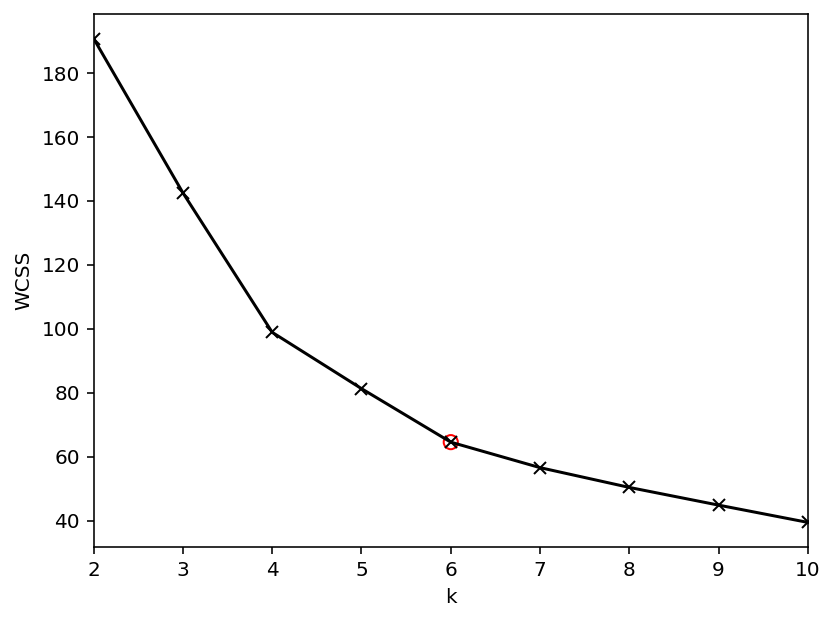

In [33]:
plot_elbow_method(2, 10, wcss, best_n)

In [34]:
kmeans = KMeans(n_clusters=best_n, n_init=20)
kmeans.fit(df_clust)

labels = kmeans.labels_

In [35]:
labels

array([2, 2, 5, 2, 5, 2, 5, 2, 5, 2, 5, 2, 5, 2, 5, 2, 5, 2, 5, 2, 5, 2,
       5, 2, 5, 2, 5, 2, 5, 2, 5, 2, 5, 2, 5, 2, 5, 2, 5, 2, 0, 2, 5, 2,
       5, 2, 0, 3, 3, 3, 0, 3, 3, 0, 0, 0, 0, 0, 3, 0, 0, 3, 0, 0, 0, 3,
       0, 0, 3, 3, 0, 0, 0, 0, 0, 3, 0, 3, 3, 0, 0, 3, 0, 0, 3, 0, 0, 3,
       3, 0, 0, 3, 0, 3, 3, 3, 0, 3, 0, 3, 3, 0, 0, 3, 0, 3, 0, 0, 0, 0,
       0, 3, 3, 3, 3, 3, 0, 0, 0, 0, 3, 3, 3, 1, 3, 1, 4, 1, 4, 1, 4, 1,
       3, 1, 3, 1, 4, 1, 3, 1, 4, 1, 3, 1, 4, 1, 4, 1, 4, 1, 4, 1, 4, 1,
       4, 1, 4, 1, 4, 1, 0, 1, 4, 1, 4, 1, 4, 1, 4, 1, 4, 1, 4, 1, 4, 1,
       4, 1, 4, 1, 4, 1, 4, 1, 4, 1, 4, 1, 4, 1, 4, 1, 4, 1, 4, 1, 4, 1,
       4, 1])

In [36]:
np.unique(labels, return_counts=True)

(array([0, 1, 2, 3, 4, 5]), array([45, 39, 24, 39, 32, 21]))

In [37]:
df_clust

array([[-0.83950617, -1.2739726 , -0.2875817 ],
       [-0.74074074, -1.2739726 ,  0.81045752],
       [-0.79012346, -1.24657534, -1.1503268 ],
       [-0.64197531, -1.24657534,  0.70588235],
       [-0.24691358, -1.21917808, -0.26143791],
       [-0.69135802, -1.21917808,  0.67973856],
       [-0.04938272, -1.19178082, -1.1503268 ],
       [-0.64197531, -1.19178082,  1.1503268 ],
       [ 1.38271605, -1.16438356, -1.22875817],
       [-0.2962963 , -1.16438356,  0.5751634 ],
       [ 1.5308642 , -1.16438356, -0.94117647],
       [-0.04938272, -1.16438356,  1.28104575],
       [ 1.08641975, -1.1369863 , -0.91503268],
       [-0.59259259, -1.1369863 ,  0.70588235],
       [ 0.04938272, -1.1369863 , -0.96732026],
       [-0.69135802, -1.1369863 ,  0.75816993],
       [-0.04938272, -1.10958904, -0.39215686],
       [-0.79012346, -1.10958904,  0.41830065],
       [ 0.79012346, -1.05479452, -0.54901961],
       [-0.04938272, -1.05479452,  1.25490196],
       [-0.04938272, -1.02739726, -0.392

In [39]:
df_clust = scaler.inverse_transform(df_clust)

In [40]:
df_clust

array([[ 420.75,  609.  , 1541.75],
       [ 461.25,  609.  , 3148.25],
       [ 441.  ,  645.5 ,  279.5 ],
       [ 501.75,  645.5 , 2995.25],
       [ 663.75,  682.  , 1580.  ],
       [ 481.5 ,  682.  , 2957.  ],
       [ 744.75,  718.5 ,  279.5 ],
       [ 501.75,  718.5 , 3645.5 ],
       [1332.  ,  755.  ,  164.75],
       [ 643.5 ,  755.  , 2804.  ],
       [1392.75,  755.  ,  585.5 ],
       [ 744.75,  755.  , 3836.75],
       [1210.5 ,  791.5 ,  623.75],
       [ 522.  ,  791.5 , 2995.25],
       [ 785.25,  791.5 ,  547.25],
       [ 481.5 ,  791.5 , 3071.75],
       [ 744.75,  828.  , 1388.75],
       [ 441.  ,  828.  , 2574.5 ],
       [1089.  ,  901.  , 1159.25],
       [ 744.75,  901.  , 3798.5 ],
       [ 744.75,  937.5 , 1388.75],
       [ 542.25,  937.5 , 2842.25],
       [ 967.5 ,  974.  ,  241.25],
       [ 663.75,  974.  , 2842.25],
       [1129.5 , 1083.5 ,  585.5 ],
       [ 623.25, 1083.5 , 3186.5 ],
       [ 947.25, 1083.5 , 1274.  ],
       [ 744.75, 1083.5 , 23

In [41]:
df_clust = df[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']]

In [42]:
df_clust.head()


,Age,Annual Income (k$),Spending Score (1-100)
0,19,15,39
1,21,15,81
2,20,16,6
3,23,16,77
4,31,17,40


In [43]:
df_clust['Cluster'] = labels

In [44]:
df_clust.head()

,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,19,15,39,2
1,21,15,81,2
2,20,16,6,5
3,23,16,77,2
4,31,17,40,5


In [45]:
centres = scaler.inverse_transform(kmeans.cluster_centers_)

In [46]:
centres

array([[56.33333333, 54.26666667, 49.06666667],
       [32.69230769, 86.53846154, 82.12820513],
       [25.25      , 25.83333333, 76.91666667],
       [26.51282051, 57.97435897, 46.69230769],
       [42.625     , 89.4375    , 17.34375   ],
       [45.52380952, 26.28571429, 19.38095238]])

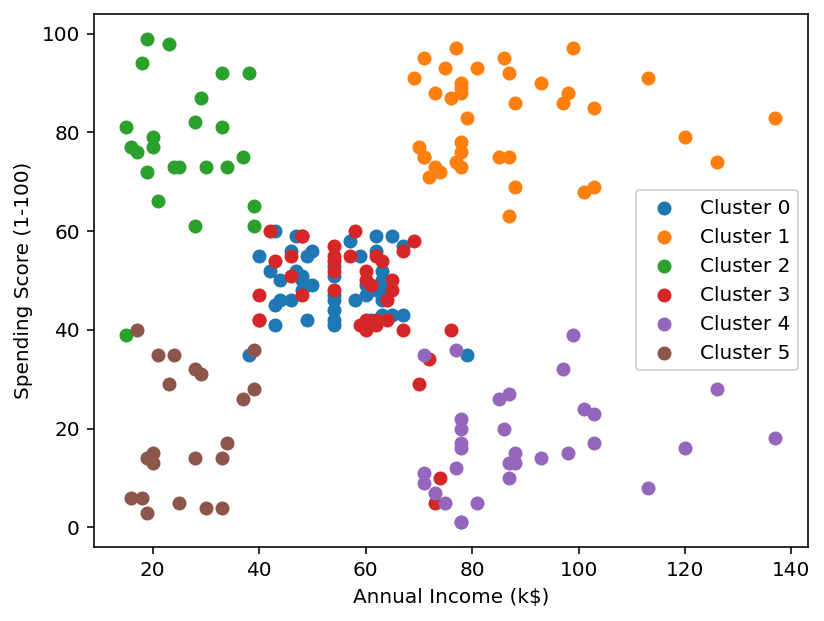

In [47]:
fig, ax = plt.subplots(dpi=144)

for i in range(6):
    ax.scatter(df_clust['Annual Income (k$)'][labels == i],
               df_clust['Spending Score (1-100)'][labels == i],
               label=f'Cluster {i}')

ax.set_xlabel('Annual Income (k$)')
ax.set_ylabel('Spending Score (1-100)')
ax.legend()

plt.show()

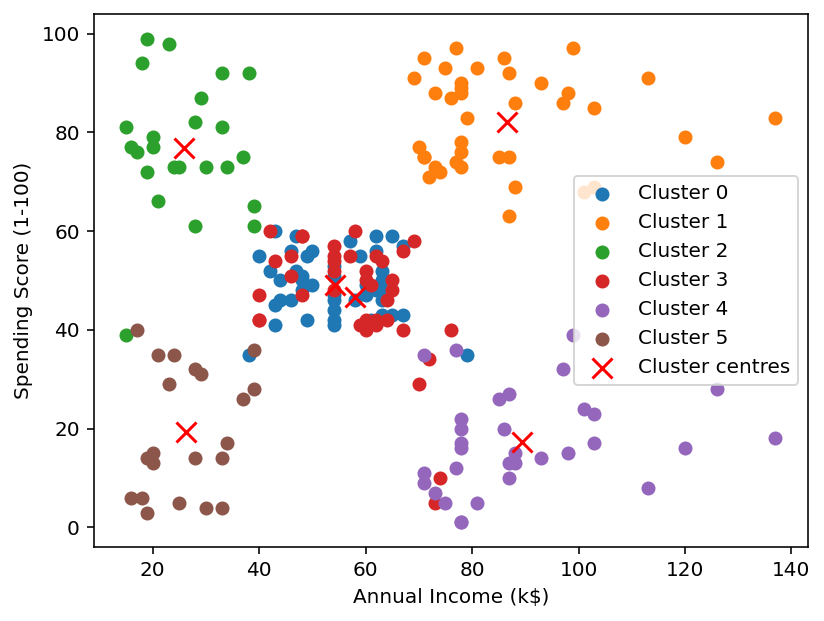

In [49]:
fig, ax = plt.subplots(dpi=144)

for i in range(6):
    ax.scatter(df_clust['Annual Income (k$)'][labels == i],
               df_clust['Spending Score (1-100)'][labels == i],
               label=f'Cluster {i}')

ax.scatter(centres[:, 1], centres[:, 2],
           marker='x', color='red', s=100,
           label='Cluster centres')

ax.set_xlabel('Annual Income (k$)')
ax.set_ylabel('Spending Score (1-100)')
ax.legend()

plt.show()

In [50]:
from scipy.optimize import curve_fit
from numpy.polynomial import Polynomial as Poly

In [51]:
def linfunc(x, a, b):
    y = a*x + b
    return y

In [52]:
x = df['Annual Income (k$)']
y = df['Spending Score (1-100)']

In [53]:
p, cov = curve_fit(linfunc, x, y)

In [54]:
sigma = np.sqrt(np.diag(cov))

In [55]:
print(f"a = {p[0]:.2f} +/- {sigma[0]:.2f}")
print(f"b = {p[1]:.2f} +/- {sigma[1]:.2f}")

a = 0.01 +/- 0.07
b = 49.61 +/- 4.61


In [56]:
xfit = np.linspace(np.min(x), np.max(x), 100)

In [57]:
yfit = linfunc(xfit, p[0], p[1])

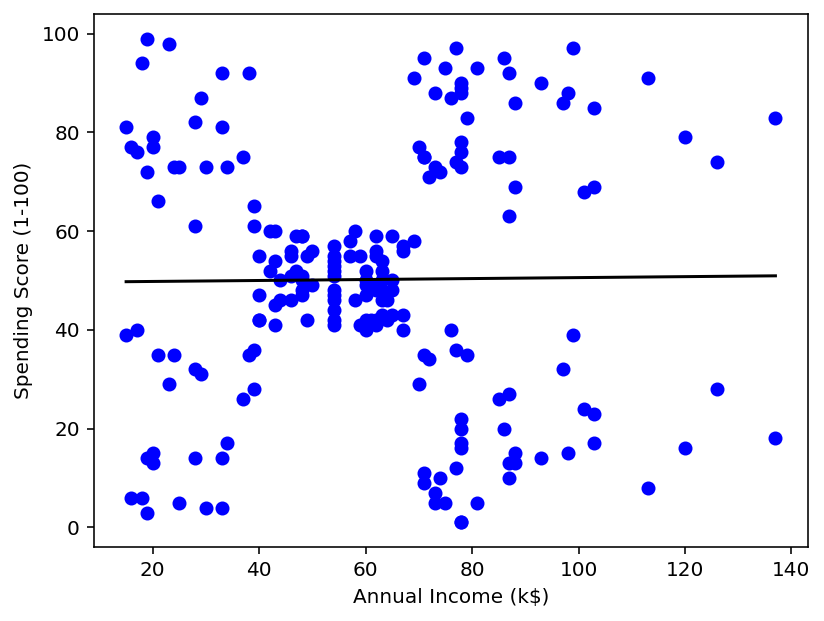

In [58]:
plt.figure(dpi=144)

plt.plot(x, y, 'bo')
plt.plot(xfit, yfit, 'k-')

plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.show()

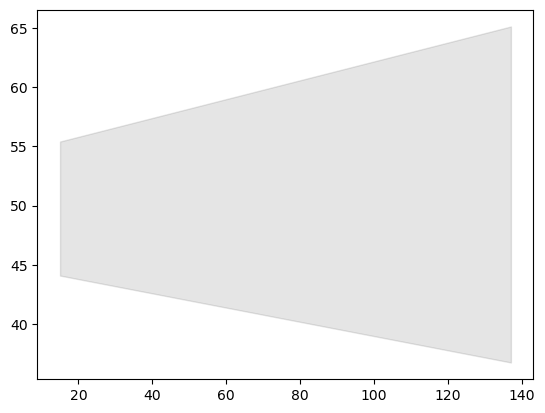

In [59]:
plt.fill_between(xfit,
                 linfunc(xfit, p[0] - sigma[0], p[1] - sigma[1]),
                 linfunc(xfit, p[0] + sigma[0], p[1] + sigma[1]),
                 color='k', alpha=0.1)

plt.show()

In [60]:
chi2 = np.sum((y - linfunc(x, *p)) ** 2)
print(f"Sum of squared residuals = {chi2:.2f}")

Sum of squared residuals = 132690.99


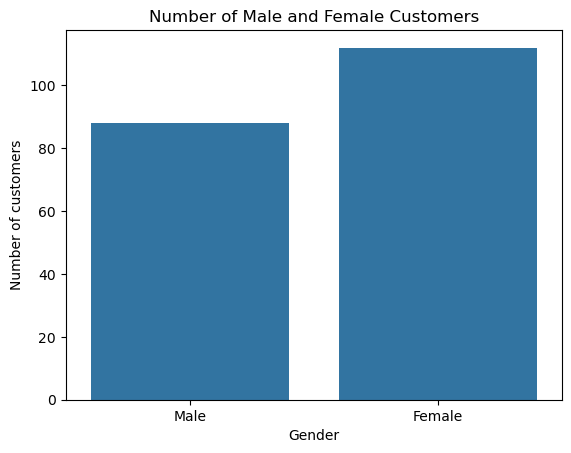

In [66]:
sns.countplot(data=df, x='Gender')

plt.xlabel('Gender')
plt.ylabel('Number of customers')
plt.title('Number of Male and Female Customers')

plt.show()

In [67]:
print(df['Gender'].value_counts())

Gender
Female    112
Male       88
Name: count, dtype: int64


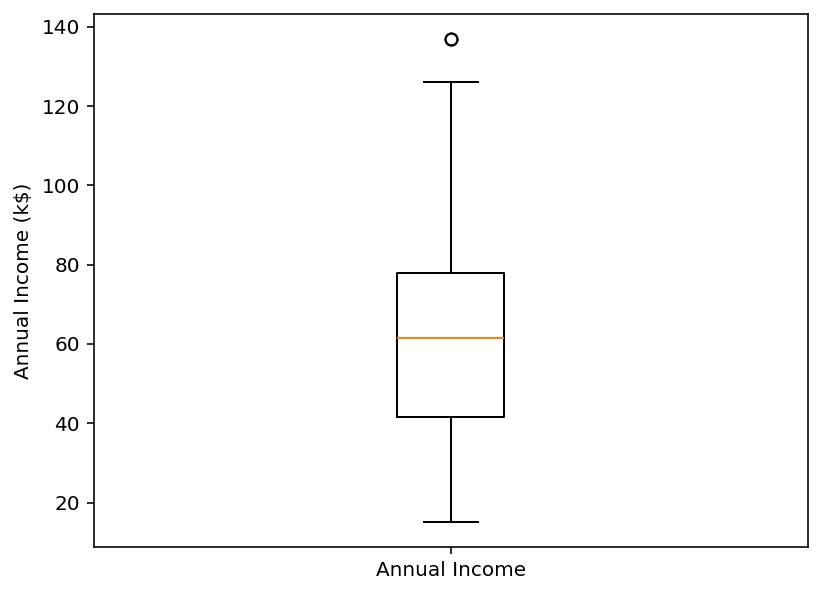

In [68]:
def plot_income_box(income):
    """
    Creates a boxplot of annual income
    """
    plt.figure(dpi=144)
    plt.boxplot(income, tick_labels=['Annual Income'])
    plt.ylabel('Annual Income (k$)')
    plt.show()
    return

plot_income_box(df['Annual Income (k$)'])

In [69]:
df['Annual Income (k$)'].describe()

count    200.000000
mean      60.560000
std       26.264721
min       15.000000
25%       41.500000
50%       61.500000
75%       78.000000
max      137.000000
Name: Annual Income (k$), dtype: float64

In [70]:
upper_fence = 78 + (1.5 * 36.5)
lower_fence = 41.5 - (1.5 * 36.5)

print(upper_fence)
print(lower_fence)

132.75
-13.25


In [71]:
df[df['Annual Income (k$)'] > 132.75]

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
198,199,Male,32,137,18
199,200,Male,30,137,83


In [72]:
print(kmeans)
print(scaler)

KMeans(n_clusters=6, n_init=20)
RobustScaler()


In [73]:
#adding new customer information
new_customer = [[25, 50, 75]]

In [74]:
new_customer_scaled = scaler.transform(new_customer)

/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RobustScaler was fitted with feature names
  warnings.warn(


In [75]:
predicted_cluster = kmeans.predict(new_customer_scaled)
print(predicted_cluster)


[2]


In [76]:
print(centres[2])

[25.25       25.83333333 76.91666667]


In [77]:
predicted_score = linfunc(50, p[0], p[1])
print(predicted_score)

50.09718257820961


In [79]:
# Fitting Prediction
# Calculate the predicted Spending Scores using the fitted linear model

yfit = linfunc(x, p[0], p[1])

In [80]:
# Calculate the residuals between actual and predicted Spending Scores

residuals = y - yfit

In [81]:
# Calculate the sum of squared residuals

sum_squared_residuals = np.sum(residuals**2)
print(sum_squared_residuals)

132690.98619640482


In [82]:
# Calculate the degrees of freedom

degrees_of_freedom = len(y) - 2
print(degrees_of_freedom)


198


In [83]:
# Calculate the Mean Squared Error (MSE)

mse = np.mean(residuals**2)
print(mse)

663.454930982024


In [84]:
# Calculate the Root Mean Squared Error (RMSE)

rmse = np.sqrt(mse)
print(rmse)

25.75761889193223


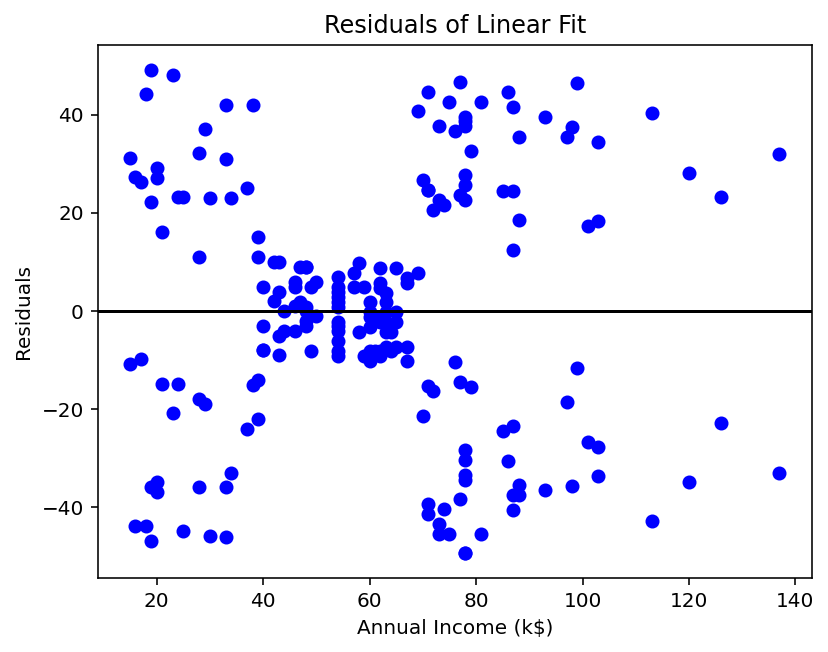

In [85]:
# Plot the residuals to assess the fitting errors

plt.figure(dpi=144)
plt.plot(x, residuals, 'bo')
plt.axhline(0, color='k')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Residuals')
plt.title('Residuals of Linear Fit')
plt.show()


In [86]:
# Calculate the correlation between Annual Income and Spending Score

correlation = df['Annual Income (k$)'].corr(df['Spending Score (1-100)'])
print(correlation)

0.009902848094037612


In [87]:
# Fit a polynomial of degree 2 to the data

p_poly = Poly.fit(x, y, 2)

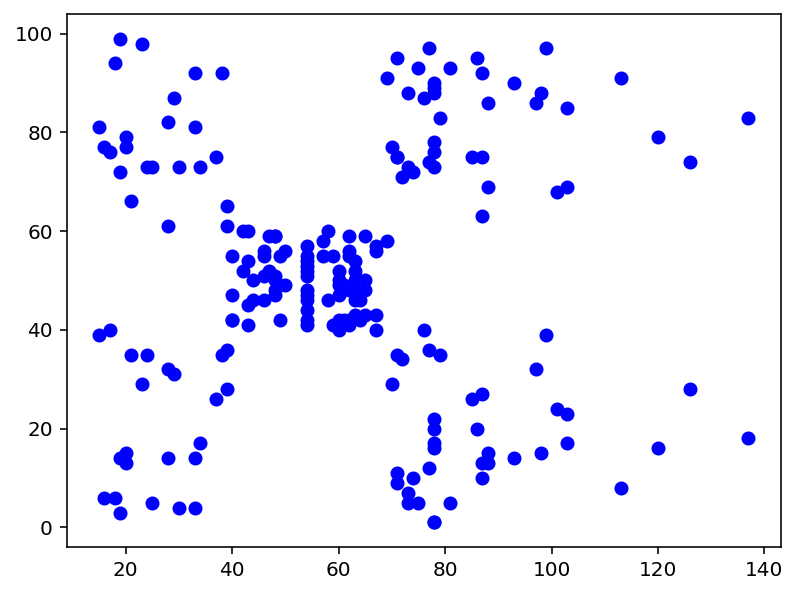

<class 'ValueError'>: x and y must have same first dimension, but have shapes (100,) and (200,)

In [90]:
# Plot the original data and compare both fitted models

plt.figure(dpi=144)

# Original data points
plt.plot(x, y, 'bo')

# Straight-line fit
plt.plot(xfit, yfit, 'k-')

# Degree-2 polynomial fit
plt.plot(*p_poly.linspace(), 'r-')

plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.show()

In [89]:
# Calculate straight-line predictions for the 100 xfit values

yline_fit = linfunc(xfit, p[0], p[1])

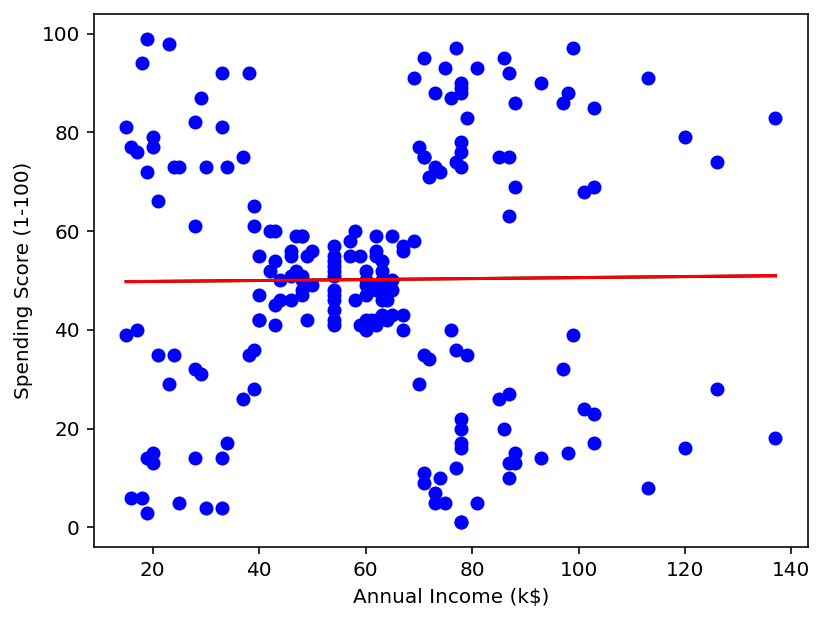

In [91]:
# Plot the original data and compare both fitted models

plt.figure(dpi=144)

# Original data points
plt.plot(x, y, 'bo')

# Straight-line fit
plt.plot(xfit, yline_fit, 'k-')

# Degree-2 polynomial fit
plt.plot(*p_poly.linspace(), 'r-')

plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.show()

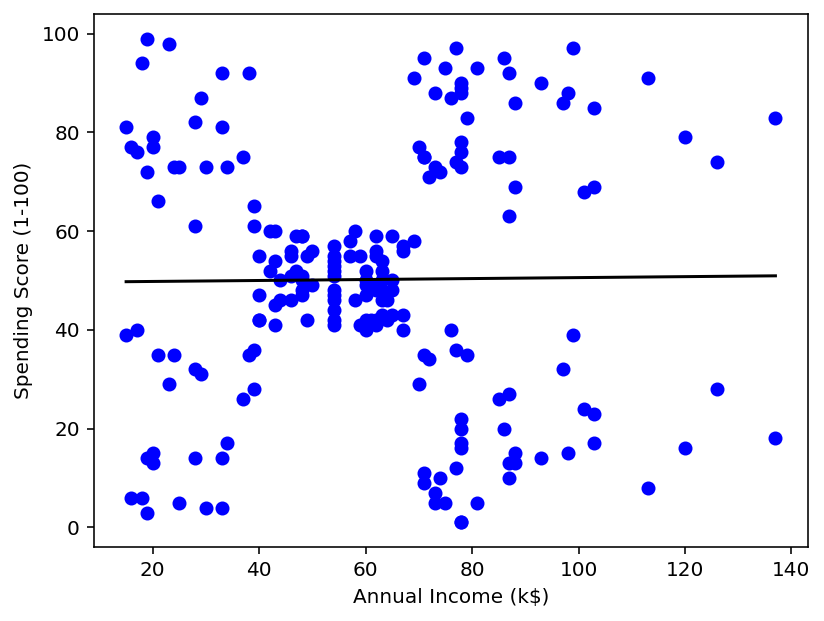

In [92]:
plt.figure(dpi=144)
plt.plot(x, y, 'bo')
plt.plot(xfit, yline_fit, 'k-')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.show()


In [93]:
# Display the polynomial coefficients

print(p_poly.convert().coef)


[4.96546543e+01 8.09199430e-03 1.26999929e-05]


In [94]:
# Calculate polynomial predictions for all customers

y_poly_fit = p_poly(x)

In [95]:
# Calculate the differences between actual and predicted scores

residuals_poly = y - y_poly_fit

# Calculate the mean squared error
mse_poly = np.mean(residuals_poly**2)

# Calculate the root mean squared error
rmse_poly = np.sqrt(mse_poly)

print(rmse_poly)

25.75761627802074


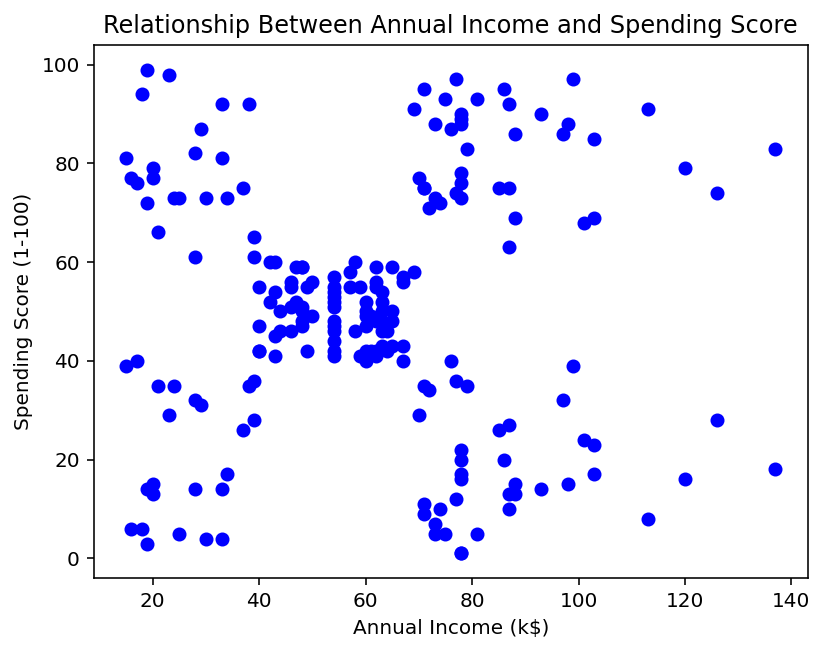

In [96]:
# Create a relational scatter plot

plt.figure(dpi=144)
plt.plot(x, y, 'bo')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('Relationship Between Annual Income and Spending Score')
plt.show()

In [97]:
# Check for missing values in the dataset

print(df.isnull().sum())

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


In [98]:
# Check for duplicate rows

print(df.duplicated().sum())

0


In [99]:
# Display the dataset information

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.1 KB


In [100]:
# Display descriptive statistics

df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [101]:
# Display the unique gender categories

print(df['Gender'].unique())

<StringArray>
['Male', 'Female']
Length: 2, dtype: str
